<a href="https://colab.research.google.com/github/porygon-tech/chemostat/blob/main/pleiotropy_effects_on_divergence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/porygon-tech/chemostat
# %cd /content/chemostat
# !git pull

fatal: destination path 'chemostat' already exists and is not an empty directory.


In [2]:
%%capture
!pip install pyfish

In [3]:
import sys
sys.path.insert(0, '/content/chemostat')
from chii.tools import *
from chii.aux import *
# import importlib
# importlib.reload(chii.tools)
# importlib.reload(chii.aux)

In [4]:
seed= 101 #array([147, 168, 183, 197, 208, 251, 264, 268, 345, 388, 389, 400, 440, 469, 542, 545, 548, 557, 617, 641, 691, 708, 722, 724, 764, 775, 798, 804, 807, 814, 901, 923, 972, 974])
M=2
S=1
V =1e15 # 1 Liter
cP=3e6

params, (X0,Y0,m0,P0,R0) = create_residents(seed, M, S, V, cP)
# params['L'] *=.8 #!!!!!!!!!!
M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = params.values()
cstar, p_star, mstar, a_star, eta = get_c_p_m_star2(params,get_cMiki=True)

print(np.all(cstar[:,I]<eta,axis=0)) # this tells whether it is really not viable. Any True will mean species is not viable
print(mstar) # IN CASE of being viable, this is the population size reached

seed: 101
[False]
[[0.00103499]]


In [5]:
#@markdown modifications
U[1]=U[0]
Fn[1]=Fn[0]
params['U']  = U
params['Fn'] = Fn
params['L'] *=1.5 #!!!!!!!!!!
params['L'][1]=params['L'][0]

M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = params.values()
cstar, p_star, mstar, a_star, eta = get_c_p_m_star2(params,get_cMiki=True)

print(np.all(cstar[:,I]<eta,axis=0)) # this tells whether it is really not viable. Any True will mean species is not viable
print(mstar) # IN CASE of being viable, this is the population size reached

[False]
[[0.00227458]]


In [6]:
#@markdown Mutator setup
seed = 894 #np.random.randint(10) # None for random seed. 644 897 894
nMutations = 70
mut = 5e-4 # mutation rate (expected number of mutants/time_unit) 1e-3

#pertb = 5e-3  # perturbation scale
U_corr=0.
T_corr=0.
U_vars= np.array([5e-3,4e-2])
T_vars= np.array([8e-4,0e-4])
# U_vars= np.array([4e-4,4e-1])
# T_vars= np.array([4e-4,0e-4])

# #@markdown Mutator setup
# rng = gen_rng(409, verbose=True) # 845
# #pertb = 5e-3  # perturbation scale
# U_corr=0. # covariance between mutation effects on Kcat and halfsat in uptake transporters
# T_corr=0. # covariance between mutation effects on Kcat and halfsat in ribosomes
# U_vars= np.array([3e-3,0e-4]) # mutation effect variances in Kcat, F for uptakers
# T_vars= np.array([0e-3,0e-4]) # mutation effect variances in Kcat, F for ribosomes
ntries=20 # max number of times tried to get all positive mutants (DEP)
extinctAfter = True # remove the strain that should go extinct from the matrix
mutation_rounds = 2000 # times to mutate population
single_molec=True
single_sector=True
single_param=True
remove_neutrals=True
smoothChoice=True
popthres=8e-12
# old_cMiki = cMiki
# # old_cstar = cstar


In [ ]:
10/1e14 # mutation rate for 10 mutations per chemostat flush for a population at steady state of 1e14 individuals
1000000/(1e-3*V/v_cell) # mutation rate for 1M mutations per chemostat flush for a population at steady state of m=1e-3

In [7]:
#@title [LOOP] Clonal interference
delta_t=15.8 # in minutes
iterations = 2000
mut = 6e-13 # mutation rate (mutations/genome/generation) 1e-3
v_cell = 1.3 # cell vol. in cubic micrometers
popthres = 1*v_cell/V # 1 cells
resolution = 21

rng = gen_rng(seed, verbose=True)
waiting_times = np.repeat(delta_t,iterations)
final_time=waiting_times.sum()
cwt = waiting_times.cumsum()

ps=deepcopy(params)
t_eval = np.linspace(0, delta_t, resolution)
M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = ps.values()

cstar, p_star, mstar, a_star, eta = get_c_p_m_star2(ps,get_cMiki=True)
# initState_equib=cstar[:,I], a_star, mstar, p_star, 1-sum(p_star)
initState_equib=cstar[:,I], a_star, mstar/2, p_star, 1-sum(p_star)
traj = integrate_system(*initState_equib, D, U, T, L, Fn, Ft, Phi, psi,(0.0, t_eval[-1]), t_eval=t_eval, optAlloc=True) # integrate
# traj = integrate_system(X0, Y0, m0, P0, R0, D, U, T, L, Fn, Ft, Phi, psi,(0.0, t_eval[-1]), t_eval=t_eval, optAlloc=True) # integrate
traj_list = [traj]
plist = [deepcopy(ps)]
parent_list=[]
mEffs_list=[]
exIX_list=[]
parent_list_degen=[]
parent_list_bulk=[]

# now we need a new loop to mutate every current strain, so we'll need to iterate over current species
# for start_end_transient in tqdm(list(zip(cwt, cwt[1:]))):
i=0
# start_end_transient = list(zip(cwt, cwt[1:]))[i]
batch_rng_seeds=rng.integers(1e3,size=iterations-1)
############################################################
for start_end_transient in tqdm(list(zip(cwt, cwt[1:]))):
    t_eval = np.linspace(*start_end_transient, resolution)

    final_densities = traj['m'][-1,:,0]
    traj['m'][-1][final_densities<popthres] = 0 # turn very low or negative popsizes to zero
    exIX=np.where(final_densities<popthres)[0];
    extinct_by_ID(ps, exIX) # actually make them go extinct
    if len(exIX)>0:
        print(f'{len(exIX)} went extinct.')

    # mt=traj['m'][-1,:,:] # m at time t
    # ct=traj['X'][-1,:,:] # c at time t

    M,S,D,U,T,L,Fn,Ft,Phi,psi,f_n,f_t,_ = ps.values()
    X0_,Y0_,m0_,P0_,R0_ = [traj[dv][-1] for dv in ('X','Y','m','P','R')] # update next init. conditions
    Y0_,m0_,R0_ = [np.delete(i0_,exIX,axis=0) for i0_ in (Y0_,m0_,R0_)]; P0_ = np.delete(P0_,exIX,axis=1) # remove extinct strain(s) for next realisation (!!!!! should go in pos.2?)
    initM = Y0_,m0_,P0_,R0_

    grs = T.T*d_AR / (1+d_dd*T.T/U*(1+Fn/X0_))-1 # growth rates for each nutrient source
    g = grs.max(0)[:,I] # highest growth rate
    N=m0_/v_cell*V # get population size
    batch_sizes = (g+D)*delta_t*mut*N # expected number of mutations
    batch_sizes = np.round(batch_sizes.T).astype(int)[0]
    rng_batch = gen_rng(batch_rng_seeds[i], verbose=False)

    k=0
    S_before = ps['S']
    tmp_parent_pack = []

    for parent, mean_n_mutations in enumerate(batch_sizes):
        ps_tmp = deepcopy(ps)
        k_i = rng_batch.poisson(mean_n_mutations)

        if k_i == 0:
            continue

        mEffs = formatted_mutEffs(
            ps['M'], U_corr, T_corr, U_vars, T_vars,
            single_molec, single_sector, single_param,
            rng_batch, nsamples=k_i
        )

        introduce_several_mutants(ps_tmp, parent, mEffs)

        extinct_by_ID(ps_tmp, np.arange(ps['S']))

        lambda_mut = get_growth_rates(ps_tmp, X0_).max(0)
        p_est = np.array([
            1 - D/(gr + D) if gr > 0 else 0
            for gr in lambda_mut
        ])

        losers = rng_batch.uniform(size=k_i) > p_est
        survivors = ~losers
        n_survivors = int(survivors.sum())

        extinct_by_ID(ps_tmp, np.where(losers)[0])

        if n_survivors == 0:
            continue

        # Record only mutants that actually establish
        tmp_parent_pack.extend([parent] * n_survivors)
        parent_list.extend([parent] * n_survivors)
        parent_list_degen.append(parent)
        mEffs_list.append([a[..., survivors] for a in mEffs])

        seeding_sizes = 1 / p_est[survivors]
        seeding_m = seeding_sizes * v_cell / V

        ps = merge_pops(ps, ps_tmp)

        initM = copy_parent_initial_conditions(
            parent, *initM, n=n_survivors
        )
        initM[1][-n_survivors:] = seeding_m[:, I]

    parent_list_bulk.append(tmp_parent_pack)

    assert ps['S'] - S_before == len(tmp_parent_pack)
    print(f'[{i}]: {ps['S']} residents')

    # traj = integrate_system_euler(X0_, *initM, D, U, T, L, Fn, Ft, Phi, psi, (t_eval[0], t_eval[-1]), t_eval=t_eval, optAlloc=True, dt=delta_t)
    traj = integrate_system_euler(X0_, *initM, *list(ps.values())[2:-3], (t_eval[0], t_eval[-1]), t_eval=t_eval, optAlloc=True, dt=delta_t)
    # traj = integrate_system(X0_, *initM, *list(ps.values())[2:-3], (t_eval[0], t_eval[-1]), t_eval=t_eval, optAlloc=True)
    traj_list.append(traj)
    plist.append(deepcopy(ps))

    exIX_list.append(exIX)

    i+=1

mEffs_list_bulk = deepcopy(mEffs_list)
mEffs_list = [
    [a[..., i:i+1] for a in group]
    for group in mEffs_list_bulk
    for i in range(group[0].shape[-1])
]

seed: 894


  0%|          | 0/1999 [00:00<?, ?it/s]

[0]: 1 residents
[1]: 1 residents
[2]: 2 residents
[3]: 3 residents
[4]: 3 residents
[5]: 3 residents
[6]: 4 residents
[7]: 5 residents
[8]: 6 residents
[9]: 6 residents
[10]: 6 residents
[11]: 6 residents
[12]: 6 residents
[13]: 6 residents
[14]: 6 residents
[15]: 6 residents
[16]: 7 residents
[17]: 7 residents
[18]: 7 residents
[19]: 7 residents
[20]: 7 residents
[21]: 7 residents
[22]: 7 residents
[23]: 7 residents
[24]: 7 residents
[25]: 7 residents
[26]: 7 residents
[27]: 7 residents
[28]: 7 residents
[29]: 7 residents
[30]: 7 residents
[31]: 7 residents
[32]: 7 residents
[33]: 7 residents
[34]: 7 residents
[35]: 7 residents
[36]: 7 residents
[37]: 7 residents
[38]: 7 residents
[39]: 8 residents
[40]: 8 residents
[41]: 8 residents
[42]: 8 residents
[43]: 8 residents
[44]: 8 residents
[45]: 8 residents
[46]: 8 residents
[47]: 8 residents
[48]: 8 residents
[49]: 9 residents
[50]: 9 residents
[51]: 9 residents
[52]: 9 residents
[53]: 9 residents
[54]: 9 residents
[55]: 9 residents
[5

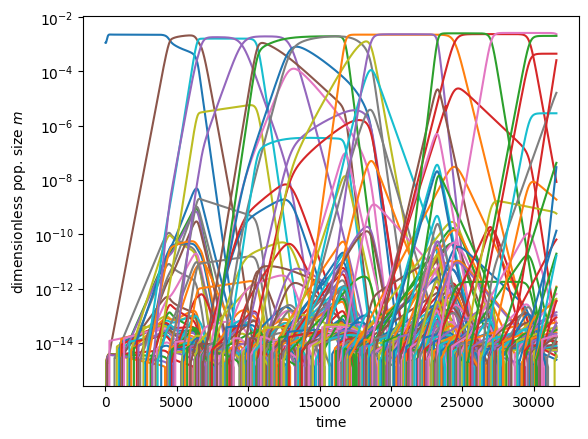

In [8]:
#@markdown important precomputes - version for hi mutation input
history, parent_of, final_population = reconstruct_history_bulk(parent_list_bulk, exIX_list)
rparent_list = [p for h in history for p in h["actual_parents"]]
child_ids = np.arange(1, len(rparent_list) + 1)

eternal_ps=deepcopy(params)

assert len(mEffs_list) == len(parent_of) - 1
# for parent, mEffs in zip(parent_list_degen, mEffs_list_bulk):
#     introduce_several_mutants(eternal_ps, parent, mEffs) # record mutant
for child_id in range(1, len(parent_of)):
    parent_id = parent_of[child_id]
    introduce_mutant(eternal_ps, parent_id, mEffs_list[child_id - 1])

assert eternal_ps["S"] == len(parent_of)


_, _, _, _, eta_eternal = get_c_p_m_star2(eternal_ps,get_cMiki=True)
eta_ratios = eta_eternal[1]/eta_eternal.sum(0)

edges = list(zip(rparent_list, child_ids))
G = nx.DiGraph(edges)
G.add_node(0)


#show trajectories
tl = [[traj['m'], traj['t']] for traj in traj_list]
x =     np.concatenate([traj['t'] for traj in traj_list])
y = merge_trajectories([traj['m'] for traj in traj_list], exIX_list).T

# plt.plot(x,y[:,1:])
plt.plot(x,y)
plt.yscale('log')
# plt.hlines(1e-11,0,traj_list[-1]['t'][-1], color='#ff0000', linestyle='--',linewidth=0.5)
plt.xlabel('time')
plt.ylabel(r'dimensionless pop. size $m$')
colors = [line.get_color() for line in plt.gca().lines] # get colors from plot above




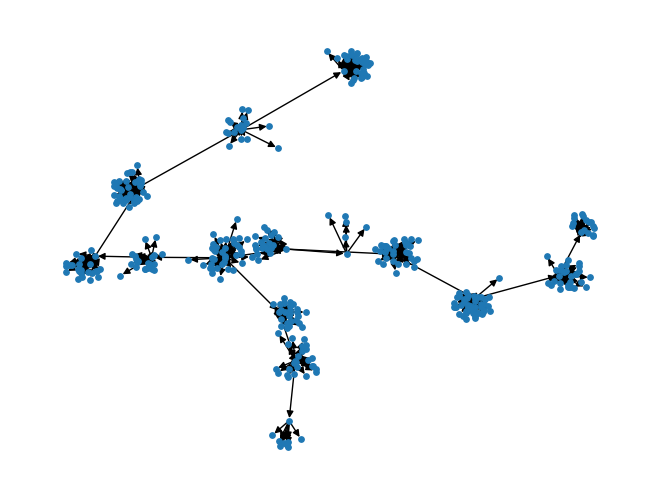

In [11]:
cmap = plt.get_cmap("Spectral")
norm = mpl.colors.Normalize(vmin=eta_ratios.min(), vmax=eta_ratios.max())
eta_colors = cmap(norm(np.concatenate([eta_ratios,[0]])))

nx.draw(G,node_size=15, pos=nx.spring_layout(G,method="energy"))

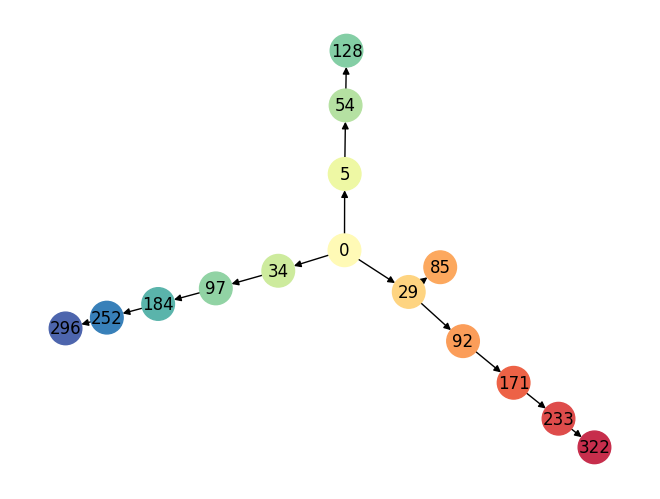

In [12]:
#@markdown see pruned graph

Gp = G.copy()
Gp,remove = prune_length1_branches(Gp,return_remove=True)

network_colors = eta_colors[:-1]
mask = np.ones(len(network_colors), dtype=bool)
mask[remove] = False
network_colors=network_colors[mask]
# eta_colors[~np.isin(np.arange(len(eta_colors)), remove)] #slower
nx.draw(Gp,node_size=550,with_labels=True, node_color=network_colors, pos=nx.spring_layout(Gp,method="energy"))

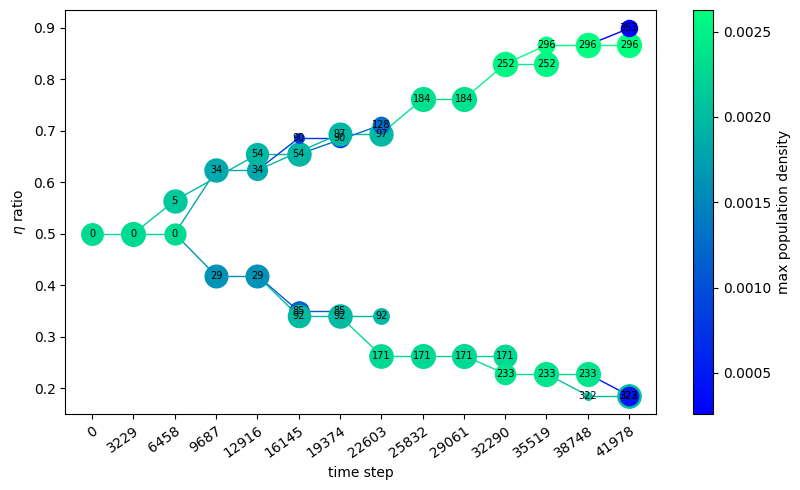

In [13]:
#@markdown sampled phylogeny
nTimeSplits=14

import matplotlib as mpl
from collections import deque


import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from collections import deque


def species_at_snapshots(pop, time_slices, threshold=0.01):
    samples = []

    for row in pop[time_slices]:
        total = row.sum()

        if total == 0:
            samples.append(np.array([], dtype=int))
        else:
            samples.append(
                np.flatnonzero(row / total > threshold)
            )

    return samples


def closest_earlier_ancestor(G, s, samples, t):
    """
    Find the closest ancestor of s that was observed at an earlier
    snapshot. Returns (snapshot_index, species).

    Persistence of the same species is treated as the closest possible
    ancestry link.
    """

    # Same species in the most recent earlier snapshot
    for tp in range(t - 1, -1, -1):
        if s in samples[tp]:
            return tp, s

    # For each species ancestor, store its most recent earlier observation
    previous = {}

    for tp in range(t - 1, -1, -1):
        for a in samples[tp]:
            if a not in previous:
                previous[a] = tp

    q = deque([s])
    seen = {s}

    while q:
        node = q.popleft()

        for p in G.predecessors(node):
            if p in seen:
                continue

            if p in previous:
                return previous[p], p

            seen.add(p)
            q.append(p)

    return None


def plot_snapshot_tree(
    G,
    samples,
    ycoord,
    pop,
    time_slices,
    c,
    cmap="winter",
    size_min=20,
    size_max=300,
):
    fig, ax = plt.subplots(figsize=(8, 5))

    species = sorted({
        s for snapshot in samples for s in snapshot
    })

    # ----- colors -----

    vals = np.asarray([c[s] for s in species])
    norm = mpl.colors.Normalize(
        vmin=vals.min(),
        vmax=vals.max()
    )
    cmap_obj = mpl.colormaps.get_cmap(cmap)

    def color_of(s):
        return cmap_obj(norm(c[s]))

    # ----- node sizes: log population at that snapshot -----

    logp = []

    for t, ss in enumerate(samples):
        for s in ss:
            p = pop[time_slices[t], s]
            logp.append(np.log10(p))

    lo = min(logp)
    hi = max(logp)

    def node_size(p):
        z = np.log10(p)

        if hi == lo:
            return 0.5 * (size_min + size_max)

        return (
            size_min
            + (size_max - size_min) * (z - lo) / (hi - lo)
        )

    # ----- ancestry edges first -----

    for t in range(1, len(samples)):
        for s in samples[t]:

            ancestor = closest_earlier_ancestor(
                G, s, samples, t
            )

            if ancestor is None:
                continue

            tp, p = ancestor

            ax.plot(
                [tp, t],
                [ycoord[p], ycoord[s]],
                color=color_of(s),
                lw=1,
                zorder=1,
            )

    # ----- snapshot nodes -----

    for t, ss in enumerate(samples):
        for s in ss:
            p = pop[time_slices[t], s]

            ax.scatter(
                t,
                ycoord[s],
                s=node_size(p),
                color=color_of(s),
                zorder=2,
            )

            # centered species ID
            ax.text(
                t,
                ycoord[s],
                str(s),
                ha="center",
                va="center",
                fontsize=7,
                zorder=3,
            )

    # actual simulation timestamps
    ax.set_xticks(range(len(time_slices)))
    ax.set_xticklabels(
        time_slices,
        rotation=35,
        ha="right",
        rotation_mode="anchor",
    )

    ax.set_xlabel("time step")

    sm = mpl.cm.ScalarMappable(
        norm=norm,
        cmap=cmap_obj,
    )
    sm.set_array([])

    cbar = fig.colorbar(sm, ax=ax)

    fig.tight_layout()

    return fig, ax, cbar

pop = y[resolution:]

timeSlices = np.linspace(
    0,
    pop.shape[0] - 1,
    nTimeSplits
).astype(int)

whosThere = species_at_snapshots(
    pop,
    timeSlices,
    threshold=0.01,
)

fig, ax, cbar = plot_snapshot_tree(
    G,
    whosThere,
    eta_ratios,
    pop,
    timeSlices,
    c=pop.max(axis=0),
    cmap="winter",
)

ax.set_ylabel(r"$\eta$ ratio")
cbar.set_label("max population density")

/tmp/ipykernel_14687/760798318.py:48: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


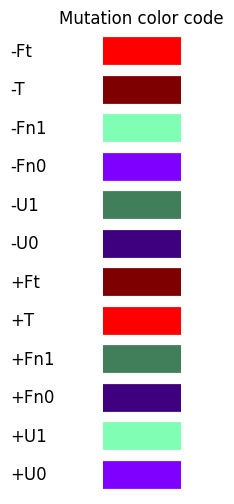

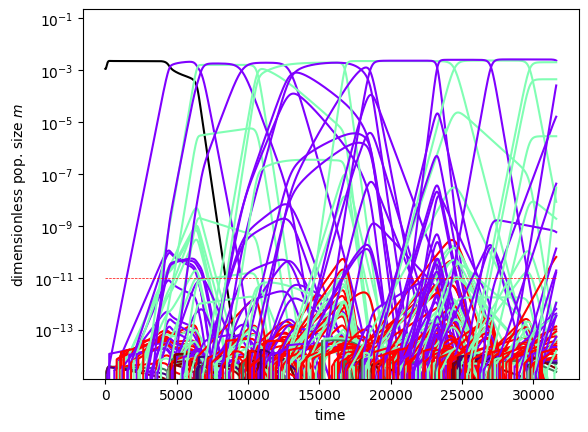

In [20]:
#@markdown Create mutation color dict
def get_mut_labels(mEffs):
    M=mEffs[0].shape[0]
    names = [["U" +str(i) for i in range(M)],
            ["Fn"+str(i) for i in range(M)],
            ["T"],
            ["Ft"]]

    decr_mask = [m<1 for m in [mEff for mEff in mEffs]]
    incr_mask = [m>1 for m in [mEff for mEff in mEffs]]
    mutlabels=[['-'+ni for ni,dmi in zip(n, dm) if dmi] for n,dm in zip(names,decr_mask)]+\
            [['+'+ni for ni,dmi in zip(n, dm) if dmi] for n,dm in zip(names,incr_mask)]
    multabelsf = [x[0] for x in mutlabels if x]
    return multabelsf
# # Apply mask to names
# [names[i] for i in range(len(names)) if incr_mask[i]]
# [names[i] for i in range(len(names)) if decr_mask[i]]
# [incr_colors[i] for i in range(len(names)) if incr_mask[i]]+\
# [decr_colors[i] for i in range(len(names)) if decr_mask[i]]

cols = cm.rainbow(np.linspace(0, 1, M+1))[:,:-1] #no alpha channel
lightness=0.5
colordict=\
dict(zip(["+U" +str(i) for i in range(M)], cols[:-1]          )) |\
dict(zip(["+Fn"+str(i) for i in range(M)], cols[:-1]*lightness)) |\
{"+T"  : cols[-1]           }                                    |\
{"+Ft" : cols[-1]*lightness }                                    |\
dict(zip(["-U" +str(i) for i in range(M)], cols[:-1]*lightness)) |\
dict(zip(["-Fn"+str(i) for i in range(M)], cols[:-1]          )) |\
{"-T"  : cols[-1]*lightness }                                    |\
{"-Ft" : cols[-1]           }

colordict_hex = dict(zip(colordict.keys(), [(lambda v: f'#{v[0]:02x}{v[1]:02x}{v[2]:02x}')((col*255).astype('int')) for col in colordict.values()]))


# Create a figure to display the colors
fig, ax = plt.subplots(figsize=(1, 6))
ax.set_xlim(0, 1)
ax.set_ylim(0, len(colordict_hex))

# Plot each color as a horizontal bar with label
for i, (label, hex_code) in enumerate(colordict_hex.items()):
    ax.axhline(i + 0.5, color=hex_code, linewidth=20)
    ax.text(-1.2, i + 0.5, f"{label}", va='center', fontsize=12, color='black')

ax.set_title("Mutation color code", fontsize=12)
ax.axis('off')  # Hide axes
plt.tight_layout()
plt.show()
# colors_incr=[cols[:-1],
#            	 cols[:-1]*lightness,
#            	 cols[-1],
#            	 cols[-1]*lightness]

# colors_decr=[cols[:-1]*lightness,
#            	 cols[:-1],
#            	 cols[-1]*lightness,
#            	 cols[-1]]


# visualize the trajectories with the mutation color scheme
mutlabels = [get_mut_labels(mEffs)[0] for mEffs in mEffs_list]
mutcolors=[colordict[lb] for lb in mutlabels]
mutcolors = [np.array([0,0,0])] + mutcolors + [np.array([0,0,0])]
mutcolors_hex = [(lambda v: f'#{v[0]:02x}{v[1]:02x}{v[2]:02x}')((col*255).astype('int')) for col in mutcolors]

x = np.concatenate([traj['t'] for traj in traj_list])
# y = np.concatenate([tli[0] for tli in tl],axis=0)[...,0]
plt.gca().set_prop_cycle('color', mutcolors_hex)

plt.plot(x,y)
plt.yscale('log')
plt.hlines(1e-11,0,traj_list[-1]['t'][-1], color='#ff0000', linestyle='--',linewidth=0.5)
plt.xlabel('time')
plt.ylabel(r'dimensionless pop. size $m$')
# plt.ylim(popthres, traj['m'].max()*200)
plt.ylim(popthres, traj_list[0]['m'].max()*200)

colors = [line.get_color() for line in plt.gca().lines] # get colors from plot above
plt.show()

# Now plot the philogeny
fig, ax = plt.subplots(figsize=(10, 10))
sizes = np.exp(y[resolution:].max(axis=0)*2e3); sizes = sizes / (10 + sizes) *500
nx.draw(G, with_labels=True, node_color=colors, font_color='white', node_size=sizes, arrows=True, pos=nx.spring_layout(G,method="energy",gravity=.2))
plt.show()


In [ ]:
#@title Muller plots

In [14]:
#@markdown Prepare data for muller plots
ytrans = np.log(np.clip(y,1e-11,np.inf)).T
ytrans-=ytrans.min()
densities = ytrans.copy()

indices = list(np.ndindex(densities.shape))
values = densities.ravel().tolist()

pairs = list(zip(indices, values))
pairs = [list(p[0]) +[p[1]] for p in pairs]

# p=pairs[0]
# list(p[0]) +p[1]

populations_df = pd.DataFrame(pairs, columns=["Id", "Step", "Pop"])
parent_tree_df = pd.DataFrame(edges, columns=["ParentId", "ChildId"])
# populations_df["Step"] = x[np.array(populations_df["Step"])]

In [15]:
#@markdown functions for visualizing
# stolen process_data2
from pyfish.core import _create_ordering_centered,_build_tree
from pyfish.core import *
from pyfish.main import *
def process_data2(pops_df, parent_df,
                 first_step=None, last_step=None, interpolate=-1, absolute=False, smooth=-1, seed=0,
                 cmap_name="rainbow", color_by=None, separate=False):
    """Load data required for plotting.
    manipulated version by porygon (original retrieved from pyfish 1.1.1 https://github.com/ICCB-Cologne/PyFish/blob/551fe11be7cc191a23eb317d77393ddd6a46654e/pyfish/core.py#L156)
    """
    min_step = pops_df["Step"].min()
    first_step = max(first_step, min_step) if first_step else min_step

    max_step = pops_df["Step"].max()
    last_step = min(last_step, max_step) if last_step else max_step

    pops_df = pops_df.loc[(pops_df["Step"] >= first_step) & (pops_df["Step"] <= last_step)]

    # populations dataframe processing
    pops_table = pops_df.set_index(['Id', 'Step'])['Pop'].unstack('Step')

    if interpolate > 0:
        if pops_table.shape[1] > 50:
            print("WARNING: interpolate is not recommened for large data")
        pops_table[first_step] = pops_table[first_step].fillna(0)
        pops_table[last_step] = pops_table[last_step].fillna(0)

        if (~pops_table.isna()).sum(axis=1).min() - 1 < interpolate:
            raise ValueError(f"For interpolate order {interpolate}, the iput data has not "
                             f"enough datapoints (at least {interpolate + 1} per sample)")

        larger_pops_table = pd.DataFrame(index=pops_table.index,
                                         columns=np.arange(first_step, last_step - 0.1, 0.1))
        larger_pops_table[pops_table.columns.astype(float)] = pops_table
        larger_pops_table = larger_pops_table.astype(float)

        linear_interpolate = larger_pops_table.interpolate(axis=1, method='linear')
        pops_table_interpolate = larger_pops_table.interpolate(axis=1, method='spline',
                                                               order=interpolate)
        pops_table_interpolate[linear_interpolate <= 0] = 0

        pops_table = pops_table_interpolate

    elif interpolate == 0:
        pops_table[first_step] = pops_table[first_step].fillna(0)
        pops_table[last_step] = pops_table[last_step].fillna(0)
        pops_table = pops_table.interpolate(axis=1, method='linear').fillna(0)

    else:
        pops_table = pops_table.fillna(0)

    steps = pops_table.columns

    if smooth is not None and smooth >= 0:
        pops_table = pd.DataFrame(gaussian_filter(pops_table, (0, smooth)),
                                  index=pops_table.index, columns=pops_table.columns)

    if absolute:
        pops_sums = pops_table.sum(axis=0)
        pop_max = pops_sums.max()
        pops_rest = pop_max - pops_sums
        pops_table.loc[-1] = pops_rest
    else:
        pop_max = None

    # Build parental relationship
    tree, ids, root_id = _build_tree(parent_df, pops_df)
    samples = pops_df['Id'].unique()
    ordering_func = _create_ordering if separate else _create_ordering_centered
    ordering = ordering_func(tree, -1 if absolute else root_id)
    ordering = [x for x in ordering if x in samples or x == -1 and absolute]

    pops_stack = pops_table.loc[ordering].astype(float)
    val, count = np.unique(pops_stack.index, return_counts=True)
    for v, c in zip(val, count):
        if c > 1:
            pops_stack.loc[v] = pops_stack.loc[v] / c

    pops_sum = pops_stack.sum(axis=0)
    pops_sum[pops_sum == 0] = 1
    pops_stack = pops_stack / pops_sum

    #--------------------------------
    # colors = _create_colors(ids, root_id, ordering, seed, cmap_name, pops_df, color_by=color_by)
    rng_lightness = gen_rng(None)
    # mutcolors2 = [mc*(rng_lightness.random(3)+1)/2 for mc in mutcolors] #create variation in lightness
    mutcolors2 = [mc*.7+rng_lightness.random(3)*.3 for mc in mutcolors] #create variation in lightness
    # mutcolors2 = mutcolors.copy()
    c2tmp = np.array(mutcolors2)[ordering]
    colors = np.hstack((c2tmp,np.ones((c2tmp.shape[0],1)))) # add alpha channel
    # print(ordering)
    #--------------------------------
    # hex_clean = np.vectorize(lambda x: f"{x:06x}")(np.arange(len(np.unique(pops_df['Id']))))
    # c2tmp = np.array([[int(h[i:i+2], 16) for i in (0, 2, 4)] for h in hex_clean])/255
    # colors = np.hstack((c2tmp,np.ones((c2tmp.shape[0],1)))) # add alpha channel
    #--------------------------------

    return pops_stack, steps, colors, pop_max

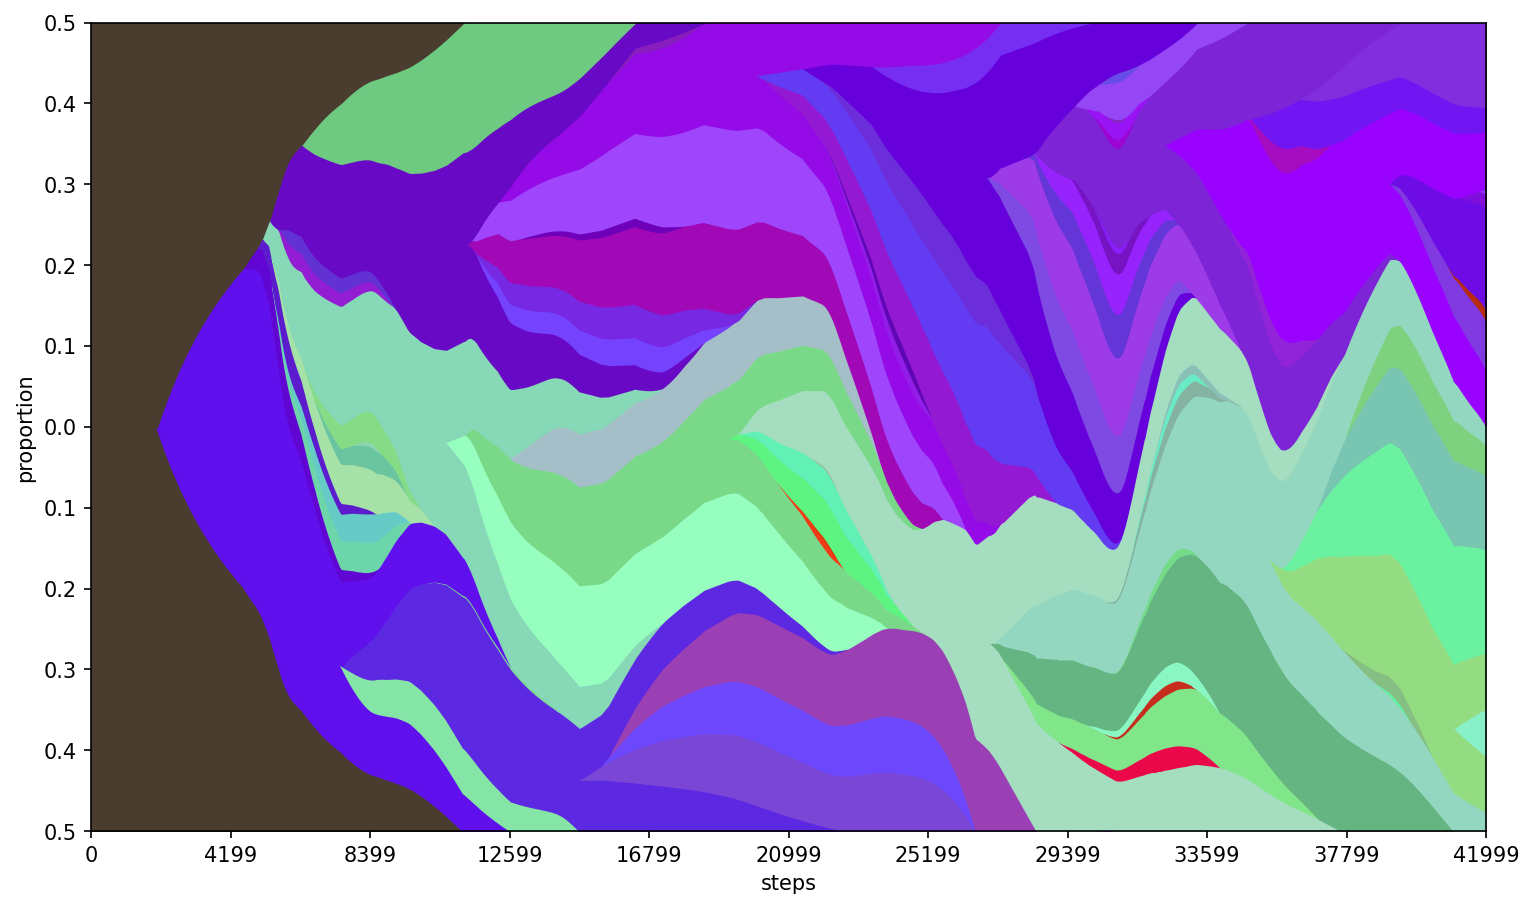

In [37]:
#@markdown first plot
data = process_data2(populations_df, parent_tree_df, interpolate=False, smooth=True)

setup_figure()
fish_plot(*data)
ax = plt.gca()
plt.show()


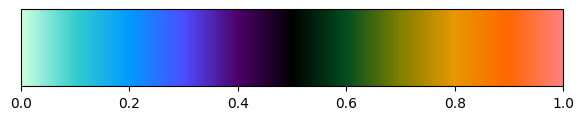

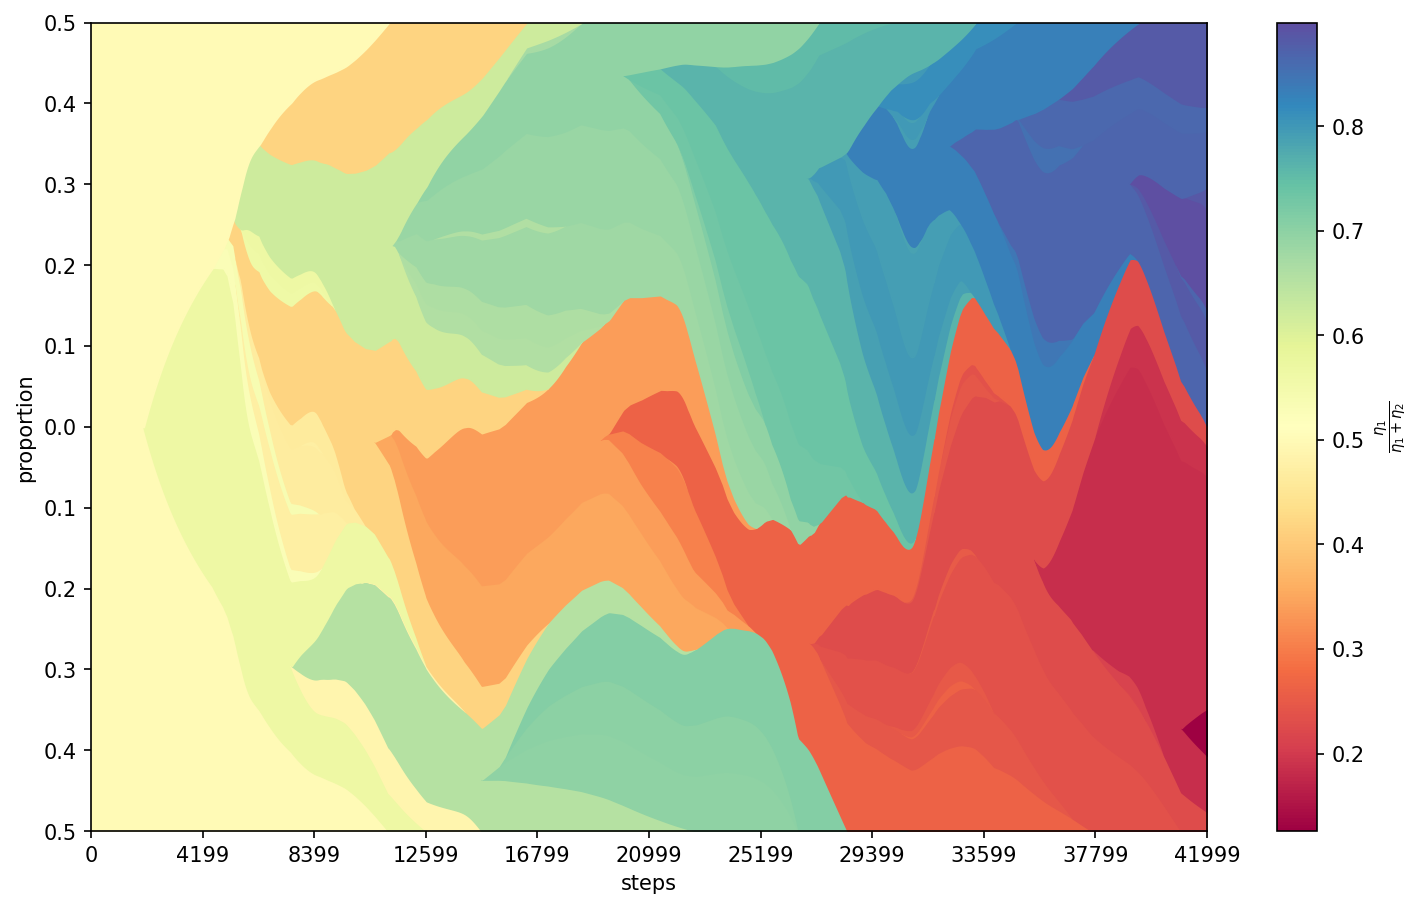

In [46]:
#@markdown my own colormap and eta ratios
from matplotlib.colors import LinearSegmentedColormap

nature = LinearSegmentedColormap.from_list(
    "eta_diverging",
    [
        (0.0, "#ccffe0"),  # low
        (0.1, "#33cccc"),
        (0.2, "#0099ff"),
        (0.3, "#4d4dff"),
        (0.4, "#4d0066"),
        (0.5, "#000000"),  # midpoint
        (0.6, "#004d1f"),
        (0.7, "#808000"),
        (0.8, "#e69900"),
        (0.9, "#ff6600"),
        (1.0, "#ff8080"),  # high
    ]
)
fig, ax = plt.subplots(figsize=(7, 1))
fig.colorbar(
    plt.cm.ScalarMappable(
        norm=plt.Normalize(0, 1),
        cmap=nature
    ),
    cax=ax,
    orientation="horizontal"
)
plt.show()

cmap = plt.get_cmap("Spectral")
# cmap=nature
# eta_colors = cmap(np.linspace(0, 1, nMutations+1))
norm = mpl.colors.Normalize(vmin=eta_ratios.min(), vmax=eta_ratios.max())
eta_colors = cmap(norm(np.concatenate([eta_ratios,[0]])))

eta_muller_colors = eta_colors[data[0].index]

setup_figure()
sm= fish_plot(data[0], data[1], eta_muller_colors, data[3])
ax = plt.gca()

sm = mpl.cm.ScalarMappable(
    # norm=mpl.colors.Normalize(vmin=0, vmax=1),
    norm=norm,
    cmap=cmap
)

plt.colorbar(sm, ax=ax, label=r"$\frac{\eta_1}{\eta_1+\eta_2}$")
plt.show()

In [53]:
add_text=True

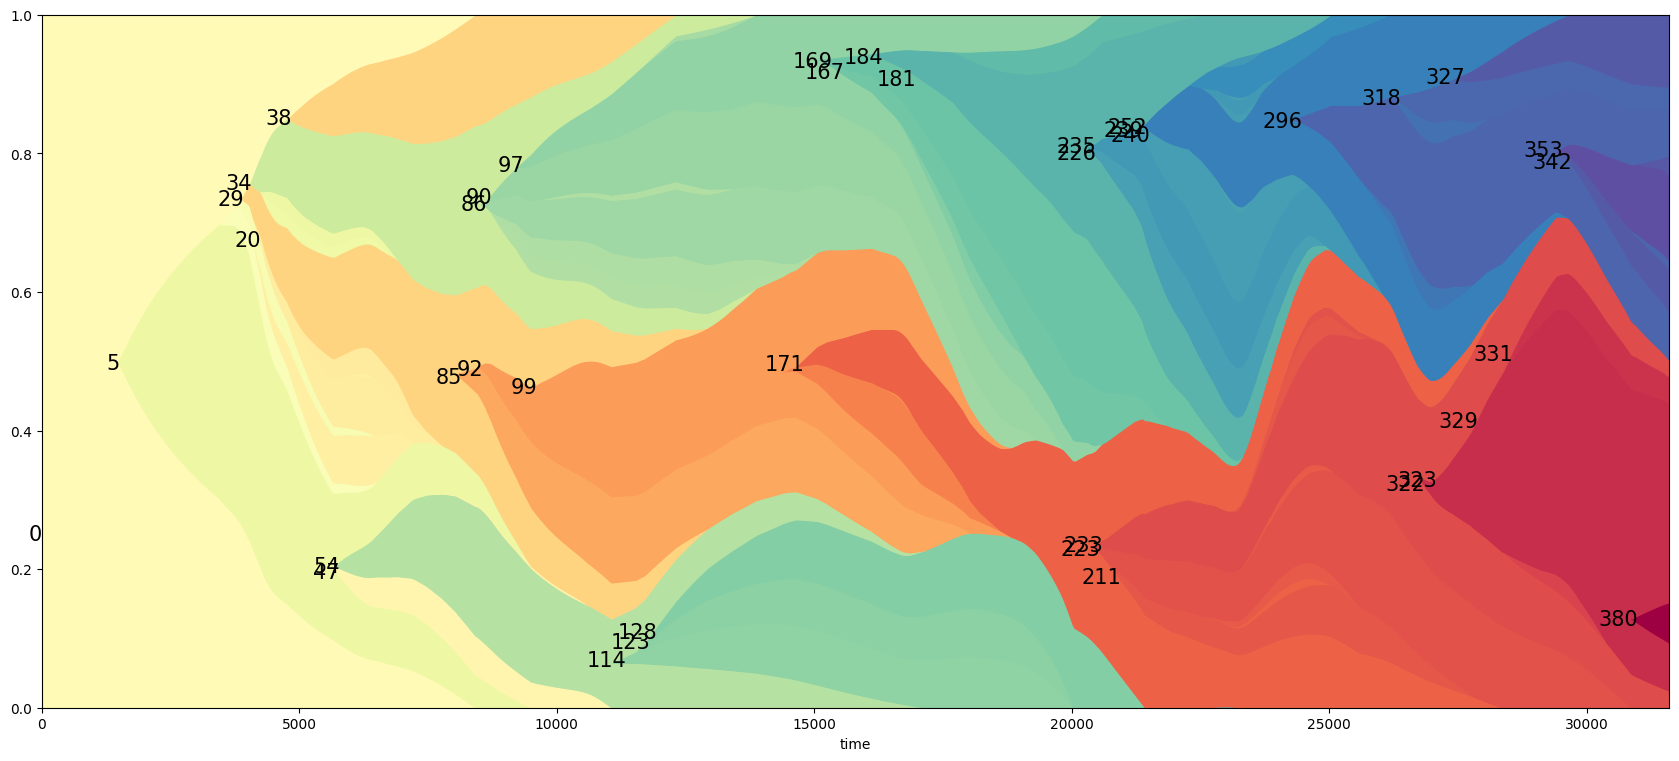

In [57]:
#@markdown reconstruct collections and change timesteps (no text)
from matplotlib.collections import PolyCollection
import matplotlib.patheffects as mpatheffects
new_verts = []
new_colors= []


for coll in ax.collections:
    coll_color = coll.get_facecolor()[0]
    # coll_color = colors[:-1][i]
    for p in coll.get_paths():
        verts = p.vertices.copy()

        # transform x -> -2x

        # verts[:, 0] **=2
        # print(np.all(verts[:, 0]%1==0))
        verts[:, 0] = x[verts[:, 0].astype('int')]
        new_verts.append(verts)
        new_colors.append(coll_color)

# re-plot transformed artists
new_coll = PolyCollection(
    new_verts,
    facecolors=new_colors,   # or choose a color
    edgecolors=new_colors
    # edgecolors='black'
)
# new_coll.sticky_edges.y[:] = [0]

fig, ax2 = plt.subplots(figsize=(21,9))
ax2.add_collection(new_coll) #

#---------------------------
# d = [(sp, verts[:,0].min()) for verts, sp in zip(new_verts, new_species)]
# # reduced = list({k: min(v for x, v in d if x == k) for k in set(x for x, _ in d)}.items())
# reptd_ixs_to_ignore = [i for i, (k, v) in enumerate(d) if any(j != i and k == d[j][0] and v > d[j][1] for j in range(len(d)))]

# for i, (verts, sp) in enumerate(zip(new_verts, new_species)):
#     if sp==0 or i in reptd_ixs_to_ignore:
#     # if sp==0:
#         continue
#     xt = np.min(verts[:, 0])
#     yt = verts[np.argmin(verts[:, 0]), 1]
#     # xt,yt = 20000,.5
#     xtl=xt+(np.random.random()-.9)*np.diff(ax2.get_xlim())[0]/12, #
#     ytl=yt+(np.random.random()-.5)*.2,
#     ax2.plot((xt,xtl[0]), (yt,ytl[0]), color='black')

#     ax2.text(
#         xtl[0],
#         ytl[0],
#         str(i),
#         fontsize=10,
#         ha="right",
#         va="center",
#         color="white",
#         fontweight="bold",
#         path_effects=[plt.matplotlib.patheffects.withStroke(linewidth=2, foreground="black")]
#     )

#---------------------------

ax2.autoscale()
# [ax2.axvline(wt,color='black',linewidth=.5) for wt in np.cumsum(waiting_times)[:-1]]
plt.xlabel('time')
vtstmp = new_verts.copy()

xyv = [(np.min(verts[:, 0]), verts[np.argmin(verts[:, 0]), 1]) for verts in vtstmp]
xyv = [vert for vert in xyv if np.all(np.array(vert)>0)]
# [ax2.scatter(*vert, marker='*', color='black') for vert in xyv]

plt.ylim(0,1)
plt.xlim(0,sum(waiting_times))


if add_text:
    stack, steps = data[:2]
    values = stack.to_numpy()
    bottom = np.cumsum(values, axis=0) - values

    for species in stack.index.unique():
        if species == -1:
            continue

        rows = np.flatnonzero(stack.index == species)
        total = values[rows].sum(axis=0)

        if total.max() < 0.05:  # minimum peak population fraction
            continue

        visible = np.flatnonzero(total > 0.01)
        if len(visible) == 0:
            continue

        j = visible[0]
        i = rows[np.argmax(values[rows, j])]

        ax2.text(
            x[j], bottom[i, j] + values[i, j] / 2,
            str(species),
            # path_effects=[mpatheffects.withStroke(linewidth=2, foreground="black")],
            # color="white",
            ha="right", va="center", fontsize=15
        )

plt.show()

In [48]:


stack, steps, _, pop_max = process_data(
    populations_df, parent_tree_df,
    interpolate=-1, smooth=-1
)

# Map sampling steps to physical recording times
x = np.array([time_by_step[s] for s in steps])

cmap = plt.get_cmap("Spectral")
norm = mpl.colors.Normalize(eta_ratios.min(), eta_ratios.max())
colors = cmap(norm(np.r_[eta_ratios, 0]))[stack.index]

fig, ax = plt.subplots(figsize=(12, 5))
fish_plot(stack, x, colors, pop_max, ax=ax, curved=True)

fig.colorbar(
    mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    label=r"$\frac{\eta_1}{\eta_1+\eta_2}$"
)

min_peak = 0.05  # species must reach at least 5% of total population

for species in stack.index.unique():
    if species == -1:
        continue

    rows = np.flatnonzero(stack.index == species)
    total = values[rows].sum(axis=0)

    if total.max() < min_peak:
        continue

    visible = np.flatnonzero(total > 0.01)
    if len(visible) == 0:
        continue

    j = visible[0]
    i = rows[np.argmax(values[rows, j])]

    ax.text(
        steps[j],
        bottom[i, j] + values[i, j] / 2,
        str(species),
        ha="left", va="center",
        fontsize=9,
        clip_on=True
    )

NameError: name 'time_by_step' is not defined